In [ ]:
import xarray as xr
import os
import numpy as np

In [ ]:
files = [f"/work/bg1581/g260200/RUN04b_JUWELS_wpile/outputs_all/out2d_{day}.nc" for day in range(1, 366)]

In [ ]:
variables = ["windSpeedX", "windSpeedY", "elevation", "depthAverageVelX", "depthAverageVelY", "sigWaveHeight", "peakPeriod", "meanWavePeriod", "TM10",
             "meanWaveNumber", "meanWaveLength", "meanWaveDirection", "meanDirSpreading",
             "SCHISM_hgrid_face_nodes", "SCHISM_hgrid_edge_nodes", "dryFlagNode", "depth",
             "SCHISM_hgrid_node_x", "SCHISM_hgrid_node_y", "SCHISM_hgrid_face_x", "SCHISM_hgrid_face_y", "SCHISM_hgrid_edge_x", "SCHISM_hgrid_edge_y",
            ]

In [ ]:
ds = xr.open_mfdataset(files, chunks="auto")

In [ ]:
ds

In [ ]:
ds = ds[variables]
for var in variables:
    ds[var] = ds[var].astype("float32")

for coord in ds.coords:
    if coord != "time":
        ds[coord] = ds[coord].astype("float32")

In [ ]:
encoding = {var: {'chunks': (24, 589428)} for var in ds.data_vars}

In [ ]:
ds

In [ ]:
zarrds = xr.open_dataset("/work/ka1176/shared_data/2025-wwm-emulator-schism/processed_RUN04b_JUWELS_wpile.zarr", engine="zarr", chunks={})
zarrds

<xarray.Dataset> Size: 597GB
Dimensions:                  (time: 8760, nSCHISM_hgrid_node: 589428,
                              nSCHISM_hgrid_edge: 1758191, two: 2,
                              nSCHISM_hgrid_face: 1168634,
                              nMaxSCHISM_hgrid_face_nodes: 4)
Coordinates:
  * time                     (time) datetime64[ns] 70kB 2020-01-01T01:00:00 ....
    SCHISM_hgrid_node_x      (nSCHISM_hgrid_node) float32 2MB dask.array<chunksize=(589428,), meta=np.ndarray>
    SCHISM_hgrid_node_y      (nSCHISM_hgrid_node) float32 2MB dask.array<chunksize=(589428,), meta=np.ndarray>
    SCHISM_hgrid_edge_x      (nSCHISM_hgrid_edge) float32 7MB dask.array<chunksize=(1758191,), meta=np.ndarray>
    SCHISM_hgrid_edge_y      (nSCHISM_hgrid_edge) float32 7MB dask.array<chunksize=(1758191,), meta=np.ndarray>
    SCHISM_hgrid_face_x      (nSCHISM_hgrid_face) float32 5MB dask.array<chunksize=(1168634,), meta=np.ndarray>
    SCHISM_hgrid_face_y      (nSCHISM_hgrid_face) float32 5MB dask.array<chunksize=(1168634,), meta=np.ndarray>
Dimensions without coordinates: nSCHISM_hgrid_node, nSCHISM_hgrid_edge, two,
                                nSCHISM_hgrid_face, nMaxSCHISM_hgrid_face_nodes
Data variables: (12/17)
    depth                    (time, nSCHISM_hgrid_node) float32 21GB dask.array<chunksize=(24, 589428), meta=np.ndarray>
    depthAverageVelX         (time, nSCHISM_hgrid_node) float32 21GB dask.array<chunksize=(24, 589428), meta=np.ndarray>
    depthAverageVelY         (time, nSCHISM_hgrid_node) float32 21GB dask.array<chunksize=(24, 589428), meta=np.ndarray>
    dryFlagNode              (time, nSCHISM_hgrid_node) float32 21GB dask.array<chunksize=(24, 589428), meta=np.ndarray>
    elevation                (time, nSCHISM_hgrid_node) float32 21GB dask.array<chunksize=(24, 589428), meta=np.ndarray>
    meanDirSpreading         (time, nSCHISM_hgrid_node) float32 21GB dask.array<chunksize=(24, 589428), meta=np.ndarray>
    ...                       ...
    SCHISM_hgrid_edge_nodes  (time, nSCHISM_hgrid_edge, two) float32 123GB dask.array<chunksize=(24, 1758191, 2), meta=np.ndarray>
    SCHISM_hgrid_face_nodes  (time, nSCHISM_hgrid_face, nMaxSCHISM_hgrid_face_nodes) float32 164GB dask.array<chunksize=(24, 1168634, 4), meta=np.ndarray>
    sigWaveHeight            (time, nSCHISM_hgrid_node) float32 21GB dask.array<chunksize=(24, 589428), meta=np.ndarray>
    TM10                     (time, nSCHISM_hgrid_node) float32 21GB dask.array<chunksize=(24, 589428), meta=np.ndarray>
    windSpeedX               (time, nSCHISM_hgrid_node) float32 21GB dask.array<chunksize=(24, 589428), meta=np.ndarray>
    windSpeedY               (time, nSCHISM_hgrid_node) float32 21GB dask.array<chunksize=(24, 589428), meta=np.ndarray>

In [ ]:
trainds_winter = zarrds.sel(time=slice("2020-01-01", "2020-05-31"))
trainds_summer = zarrds.sel(time=slice("2020-08-01", "2020-10-31"))

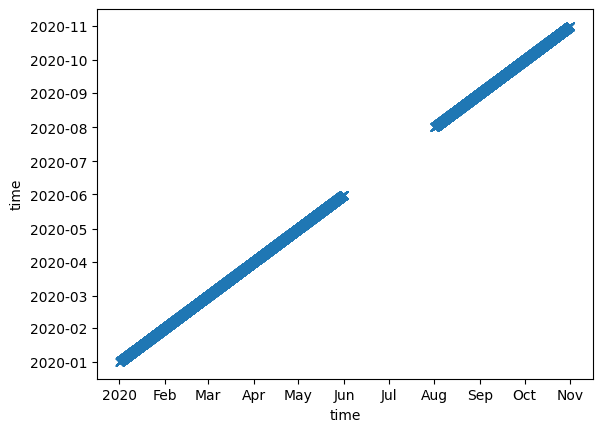

In [ ]:
trainds = xr.concat([trainds_winter, trainds_summer], dim="time")
trainds.time.plot(ls="", marker="x")

In [ ]:
for var in ["windSpeedX", "windSpeedY", "elevation", "depthAverageVelX", "depthAverageVelY", "sigWaveHeight", "peakPeriod", "meanWavePeriod", "meanWaveDirection", "meanDirSpreading","depth"]:
    print(var, ":")
    print("  mean:", trainds[var].mean().values)
    print("  std:", trainds[var].std().values)

windSpeedX :
  mean: 2.816678
  std: 5.8964024
windSpeedY :
  mean: 1.4439709
  std: 5.854472
elevation :
  mean: 0.18124886
  std: 0.88426405
depthAverageVelX :
  mean: -0.013438759
  std: 0.30307811
depthAverageVelY :
  mean: 0.0024701103
  std: 0.20047696
sigWaveHeight :
  mean: 1.3489133
  std: 0.9408989
peakPeriod :
  mean: 5.8144145
  std: 1.8600417
meanWavePeriod :
  mean: 5.0407815
  std: 1.38935
meanWaveDirection :
  mean: 242.3596
  std: 90.817184
meanDirSpreading :
  mean: 34.19352
  std: 11.826235
depth :
  mean: 23.314661
  std: 8.786188


## Statistics

In [ ]:
testds_winter = zarrds.sel(time=slice("2020-07-01", "2020-07-31"))
testds_summer = zarrds.sel(time=slice("2020-12-01", "2020-12-31"))
testds = xr.concat([testds_winter, testds_summer], dim="time")


In [ ]:
np.quantile(trainds["meanWaveDirection"], [0.01, 0.05, 0.1, 0.5, 0.9, 0.95, 0.99])

array([  0.        ,  12.54721069,  79.57111359, 267.12286377,
       326.80401611, 336.00588989, 351.56054688])

In [ ]:
np.quantile(testds["meanWaveDirection"], [0.01, 0.05, 0.1, 0.5, 0.9, 0.95, 0.99])

array([  0.        ,  25.85393715, 124.74066162, 263.87969971,
       311.93005371, 319.07611084, 344.96316528])

In [ ]:
np.unique((trainds["meanWaveDirection"] / 15).round() * 15, return_counts=True)

(array([  0.,  15.,  30.,  45.,  60.,  75.,  90., 105., 120., 135., 150.,
        165., 180., 195., 210., 225., 240., 255., 270., 285., 300., 315.,
        330., 345., 360.], dtype=float32),
 array([148271825,  54113076,  33047111,  28774795,  42159108,  48134900,
         48132357,  25712366,  34770721,  36800367,  49595630,  53417855,
         46194995,  48664722,  82614006, 176170199, 294566754, 363691267,
        381006530, 303157071, 346321171, 368733038, 285444241, 121299200,
         30307635]))

In [ ]:
np.unique((testds["meanWaveDirection"] / 15).round() * 15, return_counts=True)


(array([  0.,  15.,  30.,  45.,  60.,  75.,  90., 105., 120., 135., 150.,
        165., 180., 195., 210., 225., 240., 255., 270., 285., 300., 315.,
        330., 345., 360.], dtype=float32),
 array([ 37184782,   4859201,  10351098,   4666890,   2192398,   2082663,
          2362945,   5645176,  22138371,  22041954,  20404334,  24871223,
         25601484,  32101378,  35690279,  48159011,  58216745,  67110895,
         70628447,  68653019, 138798839, 120207533,  23349848,  12169911,
          4023596]))

In [ ]:
from matplotlib import pyplot as plt

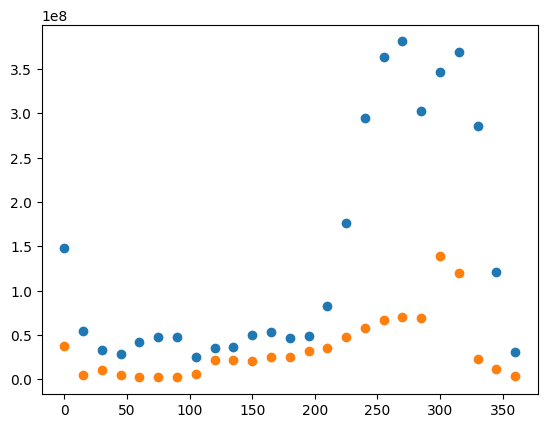

In [ ]:
plt.scatter([  0.,  15.,  30.,  45.,  60.,  75.,  90., 105., 120., 135., 150.,
        165., 180., 195., 210., 225., 240., 255., 270., 285., 300., 315.,
        330., 345., 360.], [148271825,  54113076,  33047111,  28774795,  42159108,  48134900,
         48132357,  25712366,  34770721,  36800367,  49595630,  53417855,
         46194995,  48664722,  82614006, 176170199, 294566754, 363691267,
        381006530, 303157071, 346321171, 368733038, 285444241, 121299200,
         30307635])

plt.scatter([  0.,  15.,  30.,  45.,  60.,  75.,  90., 105., 120., 135., 150.,
        165., 180., 195., 210., 225., 240., 255., 270., 285., 300., 315.,
        330., 345., 360.], [ 37184782,   4859201,  10351098,   4666890,   2192398,   2082663,
          2362945,   5645176,  22138371,  22041954,  20404334,  24871223,
         25601484,  32101378,  35690279,  48159011,  58216745,  67110895,
         70628447,  68653019, 138798839, 120207533,  23349848,  12169911,
          4023596])

In [ ]:
testds["meanWavePeriod"].plot.hist();

In [ ]:
np.quantile(testds["meanWavePeriod"], [0.01, 0.1, 0.9, 0.99])

In [ ]:
testds["meanWaveDirection"].plot.hist();

In [ ]:
(testds_winter["meanWaveDirection"] - testds_winter.shift(time=1)["meanWaveDirection"]).plot.hist();

## Create CI/CD dataset

In [ ]:
variables = ["windSpeedX", "windSpeedY", "sigWaveHeight","meanWavePeriod",
            "SCHISM_hgrid_edge_nodes",  
             "SCHISM_hgrid_node_x", "SCHISM_hgrid_node_y", "SCHISM_hgrid_edge_x", "SCHISM_hgrid_edge_y",
            ]

In [ ]:
cicd = zarrds.isel(time=slice(10*24, 15*24), nSCHISM_hgrid_node=slice(None, None, 100000))[variables]
cicd.to_zarr("/work/ka1176/caroline/gitlab/wind-wave-model-emulator/tests/cicd_data/cicd.zarr", mode="w")

In [ ]:
!zip -r cicd.zarr.zip /work/ka1176/caroline/gitlab/wind-wave-model-emulator/tests/cicd_data/cicd.zarr

In [ ]:
cicd